# E3 — logicDT: implementación propia y evaluación comparable

Implementación experimental basada en [Lau, Schikowski y Schwender (2024)](https://link.springer.com/article/10.1007/s10994-023-06488-6).
El código propio está en `logicdt_propio.py`; no se usa una librería de logicDT.
El notebook ejecuta el pipeline y la validación; `evaluacion_nuevos_e3.py` evita duplicar las
reglas del proyecto. Los resultados quedan en `resultados/e3/logicdt/`, separados de los canónicos.

Usar el kernel del entorno compartido `Precalculo/venv/`. Ejecutar todas las celdas en orden.

## Datos, variables y protocolo del tablero

Se importa la preparación canónica de `entregable3.py`, sin regenerar ni aumentar datos.
Se aplica el mismo filtro de objetivo faltante y reglas de negocio, conservando outliers válidos.
La respuesta es **nota_primer_parcial**. Son los mismos **8 predictores numéricos y 7 categóricos**.
`nota_final`, estudiante, periodo y fila fuente nunca se usan como predictores.

**Partición temporal:** train contiene los periodos anteriores a 202530 (1309 registros,
1293 estudiantes); test reserva 202530 (188 registros, 188 estudiantes). Se purgan de train
los estudiantes presentes en el periodo reservado, incluso si su objetivo de test falta.

**CV externa:** exactamente las mismas asignaciones de GroupKFold de cinco folds del tablero.
Los 1293 IDs son grupos indivisibles que se distribuyen entre cinco folds: cada fila recibe
una predicción OOF de un modelo que no vio ninguna fila de ese estudiante. Los folds no son
periodos: el periodo futuro constituye una evaluación separada. No se usa test para elegir parámetros.

**Preparación común al SVM/Ridge/Lasso/KNN:** mediana numérica, `log1p` en los tres tiempos,
StandardScaler, moda categórica y OneHotEncoder con referencia, ignorando categorías nuevas.
Cada preparación se ajusta únicamente en su subconjunto de fit, dentro del pipeline.
Las aserciones siguientes comprueban valores, orden de filas, hashes y folds contra los resultados del tablero.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

BOOK = Path.cwd()
if not (BOOK / 'entregable3.py').exists():
    BOOK = BOOK / 'Precalculo'
if not (BOOK / 'entregable3.py').exists():
    raise RuntimeError('Abre el notebook desde Precalculo o la raíz del proyecto.')
sys.path.insert(0, str(BOOK.resolve()))
from entregable3 import FEATURES, NUMERIC, CATEGORICAL, TARGET, GROUP, PERIOD, metrics
from evaluacion_nuevos_e3 import partitions, run_experiment, display_results

train, test, folds, audit = partitions()
display(pd.DataFrame([audit]))
display(pd.DataFrame({'variable': FEATURES, 'tipo': ['numérica']*8 + ['categórica']*7}))
display(pd.DataFrame([{'fold': k, 'fit_filas': len(fi), 'validacion_filas': len(va),
                      'fit_estudiantes': train.iloc[fi][GROUP].nunique(),
                      'validacion_estudiantes': train.iloc[va][GROUP].nunique(),
                      'estudiantes_compartidos': len(set(train.iloc[fi][GROUP]) & set(train.iloc[va][GROUP]))}
                     for k, (fi, va) in enumerate(folds, 1)]))
assert len(train) == 1309 and len(test) == 188
assert not set(train[GROUP]) & set(test[GROUP])
assert train[PERIOD].max() < test[PERIOD].min()
print('Integridad confirmada: fuente, 15 variables, filas, periodo y folds iguales al tablero.')

,source_rows,source_students,missing_target,test_period,train_periods,purged_overlap_rows,purged_overlap_students,train_raw,test_raw,excluded_train,excluded_test,rules_train,rules_test,train_valid,test_valid,train_students,test_students,shared_students,outliers_removed
0,1527,1506,30,202530,"[202310, 202330, 202410, 202430, 202510]",0,0,1309,188,0,0,"{'dominio': 0, 'tiempo_cero': 0, 'aprendidos_c...","{'dominio': 0, 'tiempo_cero': 0, 'aprendidos_c...",1309,188,1293,188,0,0


,variable,tipo
0,Icfes_nuevo,numérica
1,Icfes_Matematicas,numérica
2,Tiempo_empleado_en_la_verificación_de_conocimi...,numérica
3,Dominio_Inicial,numérica
4,avance_precalculo_aleks,numérica
5,Dominio_Final,numérica
6,Tiempo_Total_Tiempo,numérica
7,Tiempo_total_Aprendidos_hora,numérica
8,Categoria_temas_inicial,categórica
9,Categoria_temas_final,categórica


,fold,fit_filas,validacion_filas,fit_estudiantes,validacion_estudiantes,estudiantes_compartidos
0,1,1047,262,1035,258,0
1,2,1047,262,1034,259,0
2,3,1047,262,1034,259,0
3,4,1047,262,1034,259,0
4,5,1048,261,1035,258,0


Integridad confirmada: fuente, 15 variables, filas, periodo y folds iguales al tablero.


## Qué se implementa del método y qué se adapta

1. Un **literal** es una variable binaria o su negación. Un término es la conjunción AND de
   hasta dos literales, por ejemplo `(Dominio_Final > corte) AND NOT(categoría_programa)`.
2. Un estado es un conjunto de hasta 3 o 5 términos. El árbol recibe sus valores lógicos,
   no solamente los predictores individuales. Esto permite explorar interacciones con poco efecto marginal.
3. Se busca el conjunto mediante **recocido simulado**: añadir, eliminar o reemplazar un término,
   o negar un literal. Una propuesta mejor se acepta; una peor se acepta con probabilidad
   `exp((MSE_actual − MSE_propuesto)/temperatura)`. Se conserva siempre la mejor solución visitada.
4. El árbol binario se construye minimizando la suma de errores cuadrados de sus hojas.
   La profundidad y el mínimo de 40 registros por hoja limitan el sobreajuste.

**Adaptaciones explícitas:** el artículo está diseñado para entradas binarias. Las ocho variables
numéricas se convierten internamente en indicadores `x > cuantil`, con cuantiles .25, .50 y .75
aprendidos solo en fit; las dummies categóricas ya son binarias. Por tanto, se conservan las variables
originales y el preprocesamiento externo del tablero, pero existe una discretización adicional propia
del modelo. Las hojas se comparan como media (núcleo de logicDT) o **Ridge multivariable sobre los
ocho numéricos transformados**, una adaptación inspirada en la extensión de regresión en nodos del
artículo. No es la misma formulación ni el mismo criterio de razón de verosimilitud del paquete R.

Se usa enfriamiento geométrico, 120 propuestas por reinicio y 2 reinicios con semilla 42.
Es un presupuesto exploratorio acotado; el artículo recomienda búsquedas considerablemente mayores.
No se implementan bagging ni importancia de interacciones, y **no se atribuye la garantía asintótica
del artículo a esta adaptación finita**. Se puede ampliar `n_iter` en un nuevo experimento,
decidiéndolo con train/CV y no en respuesta al resultado de test.

In [2]:
from evaluacion_nuevos_e3 import logic_pipeline, LOGIC_GRID
from logicdt_propio import LogicDTRegressor
from sklearn.model_selection import ParameterGrid
import inspect

pipeline = logic_pipeline()
display(pipeline)
display(pd.DataFrame(list(ParameterGrid(LOGIC_GRID))))
print('Configuraciones:', len(list(ParameterGrid(LOGIC_GRID))))
print('Ajustes en CV: 5 × 5 × 8 + 5 × 8 = 240, más 6 refits.')
# El código es propio y se puede inspeccionar/editar en el módulo adyacente.
print(inspect.getsource(LogicDTRegressor._terms_matrix))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_log', ...), ('num_plain', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: floa

,modelo__leaf_model,modelo__max_depth,modelo__max_terms,modelo__ridge_alpha
0,mean,2,3,NaN
1,mean,2,5,NaN
2,mean,3,3,NaN
3,mean,3,5,NaN
4,ridge,2,3,1.0
5,ridge,2,3,10.0
6,ridge,2,5,1.0
7,ridge,2,5,10.0


Configuraciones: 8
Ajustes en CV: 5 × 5 × 8 + 5 × 8 = 240, más 6 refits.
    @staticmethod
    def _terms_matrix(bits, terms):
        return np.column_stack([
            np.logical_and.reduce([~bits[:, j] if neg else bits[:, j]
                                   for j, neg in term]) for term in terms])



## Selección anidada sin fuga de información

Para cada fold externo, GridSearchCV compara ocho configuraciones en cinco folds internos
por estudiante del subconjunto externo de entrenamiento. Cada candidato vuelve a ajustar
imputación, escalas, vocabulario, cuantiles, términos y árbol. Selecciona el menor RMSE interno,
reajusta en todo ese fit externo y predice la validación externa. Finalmente se repite la búsqueda
interna usando todo train y se evalúa el test temporal una vez fijados los parámetros.

La grilla contiene cuatro árboles con hojas medias (3/5 términos × profundidad 2/3) y cuatro
con hojas Ridge (3/5 términos × alpha 1/10, profundidad 2). Las categorías no vistas se manejan
con el mismo encoder del SVM. No se escogen cortes ni términos usando datos de validación.

In [3]:
# Reutiliza únicamente resultados completos cuyo manifiesto coincide con los archivos actuales.
# force=True ejecuta de nuevo toda la evaluación; no cambia el protocolo ni las grillas.
report = run_experiment('logicdt', force=False)
display(pd.DataFrame(report['fold_audit']))
print('Parámetros finales:', report['best_params'])

logicdt: fold externo 1/5, fit=1047, validación=262


logicdt: fold 1 RMSE=0.768409, 9.1s


logicdt: fold externo 2/5, fit=1047, validación=262


logicdt: fold 2 RMSE=0.946899, 8.3s


logicdt: fold externo 3/5, fit=1047, validación=262


logicdt: fold 3 RMSE=0.867928, 7.6s


logicdt: fold externo 4/5, fit=1047, validación=262


logicdt: fold 4 RMSE=0.796669, 9.1s


logicdt: fold externo 5/5, fit=1048, validación=261


logicdt: fold 5 RMSE=0.824141, 8.6s


logicdt: ajuste final exclusivamente en train; luego evaluación test 202530


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,fold,fit_rows,validation_rows,shared_students,best_params,seconds
0,1,1047,262,0,"{'modelo__leaf_model': 'ridge', 'modelo__max_d...",9.108883
1,2,1047,262,0,"{'modelo__leaf_model': 'ridge', 'modelo__max_d...",8.298086
2,3,1047,262,0,"{'modelo__leaf_model': 'ridge', 'modelo__max_d...",7.562021
3,4,1047,262,0,"{'modelo__leaf_model': 'ridge', 'modelo__max_d...",9.064343
4,5,1048,261,0,"{'modelo__leaf_model': 'ridge', 'modelo__max_d...",8.648540


Parámetros finales: {'modelo__leaf_model': 'ridge', 'modelo__max_depth': 2, 'modelo__max_terms': 5, 'modelo__ridge_alpha': 10.0}


## Métricas e interpretación

Se llama directamente a `entregable3.metrics`: **RMSE**, **MAE**, **MAPE (%)** y **R²**,
en la escala original de la nota, sin recortar las predicciones. Menor error es mejor;
mayor R² es mejor. MAPE conserva la definición del tablero y es sensible a notas cercanas a cero.

Se reportan los cinco resultados externos, su media y desviación estándar poblacional (`ddof=0`),
y las métricas sobre todas las predicciones OOF reunidas (no necesariamente iguales a la media por fold).
El test temporal se presenta por separado. Los IC del 95% se obtienen con 1000 réplicas bootstrap
por estudiante, semilla 42; la diferencia frente al SVM usa las mismas muestras en cada réplica.
Un intervalo de diferencia que incluye cero no respalda una mejora concluyente. Estos intervalos
son condicionales al modelo ajustado y no incluyen la variabilidad de volver a entrenarlo.

La comparación con los modelos existentes es descriptiva: el test del tablero ya fue inspeccionado
en fases anteriores. No equivale a una nueva prueba ciega. No se promete superar los modelos previos.

,metrica,media_cv,sd_cv,OOF_agrupado
0,RMSE,0.84081,0.06238,0.84313
1,MAE,0.66559,0.04451,0.66560
2,MAPE (%),25.00494,2.06954,25.00456
3,R²,0.42922,0.08522,0.43086


,metrica,estimacion,IC_2.5%,IC_97.5%
0,RMSE,0.92644,0.84211,1.01407
1,MAE,0.76095,0.68649,0.84209
2,MAPE (%),29.65884,23.88915,36.45393
3,R²,0.43010,0.32842,0.51129


,Modelo,RMSE,MAE,MAPE (%),R²
0,SVM lineal,0.92771,0.75544,29.66456,0.42854
1,Dummy media,1.25606,1.10447,42.31451,-0.04757
2,KNN,0.92327,0.75403,29.58450,0.43399
3,Ridge,0.91709,0.75451,29.57214,0.44155
4,Lasso,0.91965,0.75304,29.55197,0.43842
5,Random Forest,0.93964,0.76585,29.73202,0.41375
6,XGBoost,0.90627,0.72892,28.40477,0.45464
7,logicDT propio (adaptado),0.92644,0.76095,29.65884,0.43010


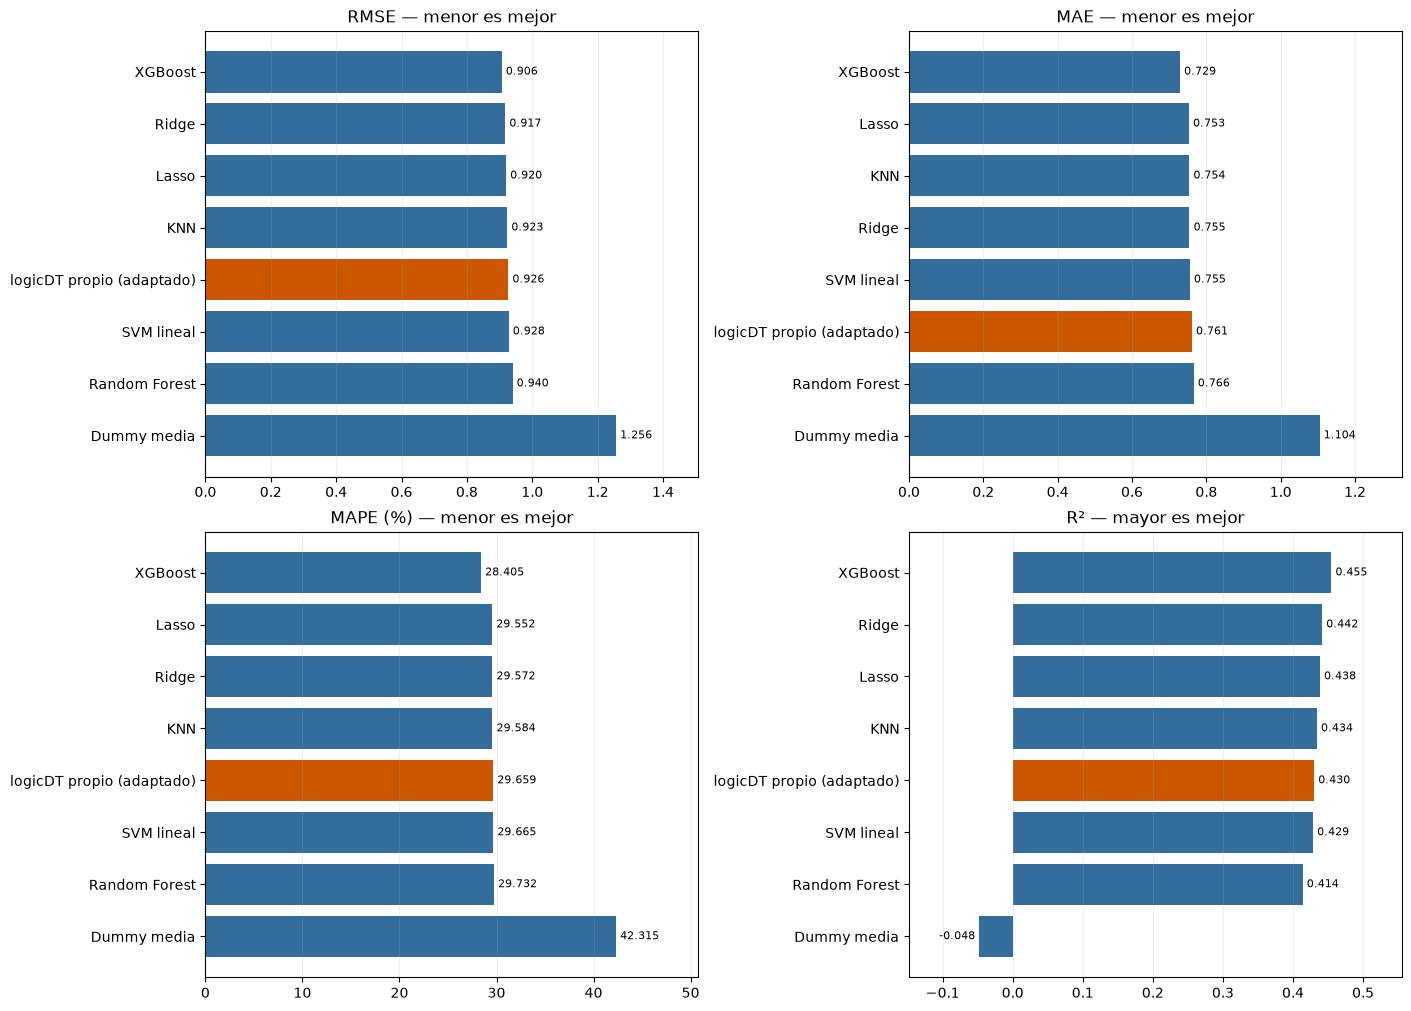

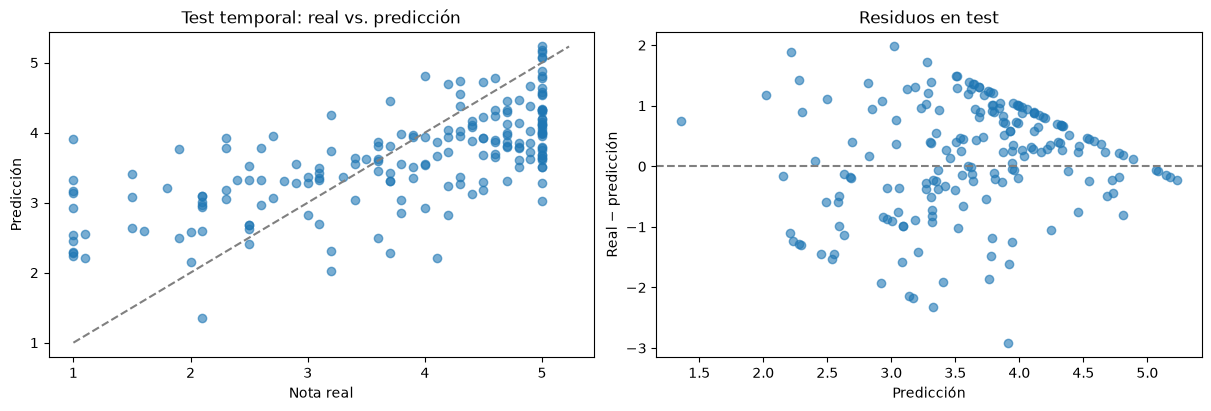

,metrica,nuevo_menos_SVM,IC_2.5%,IC_97.5%
0,RMSE,-0.00127,-0.03641,0.02984
1,MAE,0.00551,-0.03175,0.04002
2,MAPE (%),-0.00572,-0.96561,1.00217
3,R²,0.00156,-0.03712,0.04640


In [4]:
display_results(report)
display(pd.DataFrame(report['paired_vs_svm']).round(5))

## Reglas del modelo final y trayectoria de búsqueda

Los cortes impresos están en la **escala transformada** por el pipeline, no en puntos brutos
de ICFES o ALEKS. `<=` representa la negación del indicador `>`. Un término seleccionado puede
no utilizarse en el árbol final; la tabla de nodos identifica los términos efectivamente usados.
En cada nodo, la rama izquierda corresponde a término falso y la derecha a verdadero.
Las reglas representan asociaciones predictivas, no efectos causales.

,termino,regla_en_escala_transformada
0,0,num_plain__avance_precalculo_aleks > -0.85937 ...
1,1,cat__Categoria_temas_inicial_1 Repaso de álgeb...
2,2,cat__programa_en_matricula_Ingeniería Electrón...
3,3,cat__division_en_matricula_División de Ciencia...
4,4,cat__Mat_Curso_Asignatura_Relacionada_MAT1101 ...


,nodo,registros_fit,termino_split,tipo
0,raíz,1309,4.0,nodo
1,raíz → falso,799,1.0,nodo
2,raíz → falso → falso,387,NaN,ridge
3,raíz → falso → verdadero,412,NaN,ridge
4,raíz → verdadero,510,3.0,nodo
5,raíz → verdadero → falso,64,NaN,ridge
6,raíz → verdadero → verdadero,446,NaN,ridge


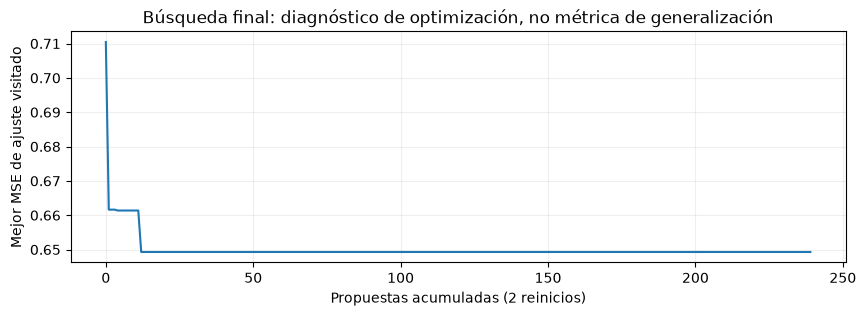

In [5]:
import joblib
import matplotlib.pyplot as plt
folder = BOOK / 'resultados/e3/logicdt'
fitted = joblib.load(folder / 'modelo.joblib')
estimator = fitted.named_steps['modelo']
display(pd.DataFrame(estimator.describe_terms(fitted.named_steps['preprocesamiento'].get_feature_names_out())))
nodes = []
def visit(node, path='raíz'):
    nodes.append({'nodo': path, 'registros_fit': node['n'], 'termino_split': node.get('term'),
                  'tipo': 'nodo' if 'term' in node else estimator.leaf_model})
    if 'term' in node:
        visit(node['left'], path + ' → falso')
        visit(node['right'], path + ' → verdadero')
visit(estimator.tree_)
display(pd.DataFrame(nodes))
trace = pd.read_csv(folder / 'recocido_final.csv')
plt.figure(figsize=(10, 3))
plt.plot(trace.best_mse.to_numpy())
plt.xlabel('Propuestas acumuladas (2 reinicios)')
plt.ylabel('Mejor MSE de ajuste visitado')
plt.title('Búsqueda final: diagnóstico de optimización, no métrica de generalización')
plt.grid(alpha=.2)
plt.show()

## Archivos y reproducibilidad

Se guardan reporte JSON, cuatro métricas por fold, ocho candidatos por búsqueda interna,
predicciones OOF/test sin IDs, términos, trayectoria y pipeline final serializado.
Los hashes vinculan fuente, protocolo y módulos de implementación; si cambian se recalcula.
El árbol serializado contiene coeficientes y reglas, no la tabla de estudiantes.
Los notebooks históricos y los resultados del tablero se preservan.

In [6]:
print(json.dumps(report['versions'], indent=2, ensure_ascii=False))
print('Resultados:', folder.resolve())

{
  "numpy": "2.3.5",
  "pandas": "3.0.1",
  "scikit-learn": "1.9.1",
  "scipy": "1.18.1"
}
Resultados: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\resultados\e3\logicdt
